# Stock Market Price Prediction Using Machine Learning
### Internship minor project • reproducible historical experiment
**Objective:** predict the next observed price for AMZN, DPZ, NFLX and BTC using information available at the current observation. BTC is a cryptocurrency, included because it appears in the supplied dataset.

**Dataset:** user-supplied `portfolio_data.csv`, described by the user as this exact  dataset, license, currency, price field and corporate-action adjustments have not been supplied or verified. Prices are therefore reported in **dataset price units**.

**Research question:** can Ridge regression or a Random Forest improve on persistence (tomorrow's price equals today's price) on a held-out chronological test set?


In [1]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import joblib
from IPython.display import display, Markdown

SEED = 42
DATA_PATH = Path("portfolio_data.csv")
OUT = Path("results")
OUT.mkdir(exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 115})
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)

Python: 3.13.3 | scikit-learn: 1.9.1


## 1. Load and validate the data
Dates use month/day/year. Reject missing, nonnumeric, nonpositive or duplicate observations rather than silently inventing prices. Sort chronologically. Weekends and other missing dates are not filled: the target is the **next recorded observation**, which is not necessarily the next calendar day, especially for BTC.

In [2]:
raw = pd.read_csv(DATA_PATH)
assets = ["AMZN", "DPZ", "BTC", "NFLX"]
assert set(raw.columns) == {"Date", *assets}, "Unexpected CSV schema"
raw["Date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y", errors="raise")
assert not raw["Date"].duplicated().any(), "Duplicate dates need review"
prices = raw.set_index("Date").sort_index()[assets].apply(pd.to_numeric, errors="raise")
assert np.isfinite(prices.to_numpy()).all(), "Missing or infinite prices"
assert (prices > 0).all().all(), "Nonpositive prices"
assert prices.index.is_monotonic_increasing
print(f"{len(prices):,} rows | {prices.index.min().date()} to {prices.index.max().date()}")
print("Missing values:", int(prices.isna().sum().sum()))
display(prices.head())
display(prices.describe().round(3))
audit = {"rows": len(prices), "start": str(prices.index.min().date()),
         "end": str(prices.index.max().date()), "missing": int(prices.isna().sum().sum()),
         "sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()}
(OUT / "data_audit.json").write_text(json.dumps(audit, indent=2))

1,520 rows | 2013-05-01 to 2019-05-14
Missing values: 0


,AMZN,DPZ,BTC,NFLX
Date,,,,
2013-05-01,248.229996,51.190983,106.250000,30.415714
2013-05-02,252.550003,51.987320,98.099998,30.641428
2013-05-03,258.049988,52.446388,112.900002,30.492857
2013-05-06,255.720001,53.205257,109.599998,30.098572
2013-05-07,257.730011,54.151505,113.199997,29.464285


,AMZN,DPZ,BTC,NFLX
count,1520.000,1520.000,1520.000,1520.000
mean,821.542,146.772,2421.466,147.668
std,518.443,72.192,3310.894,107.641
min,248.230,51.191,69.660,29.464
25%,364.360,84.994,340.905,62.851
50%,686.460,127.168,625.305,104.000
75%,1121.288,202.455,3874.912,192.207
max,2039.510,298.636,18972.320,418.970


162

## 2. Exploratory analysis
Normalize each series to 100 to compare relative movement. Correlation uses observation-to-observation returns rather than trending price levels. These plots describe the full dataset; no feature or parameter choices are derived from the held-out test outcomes.

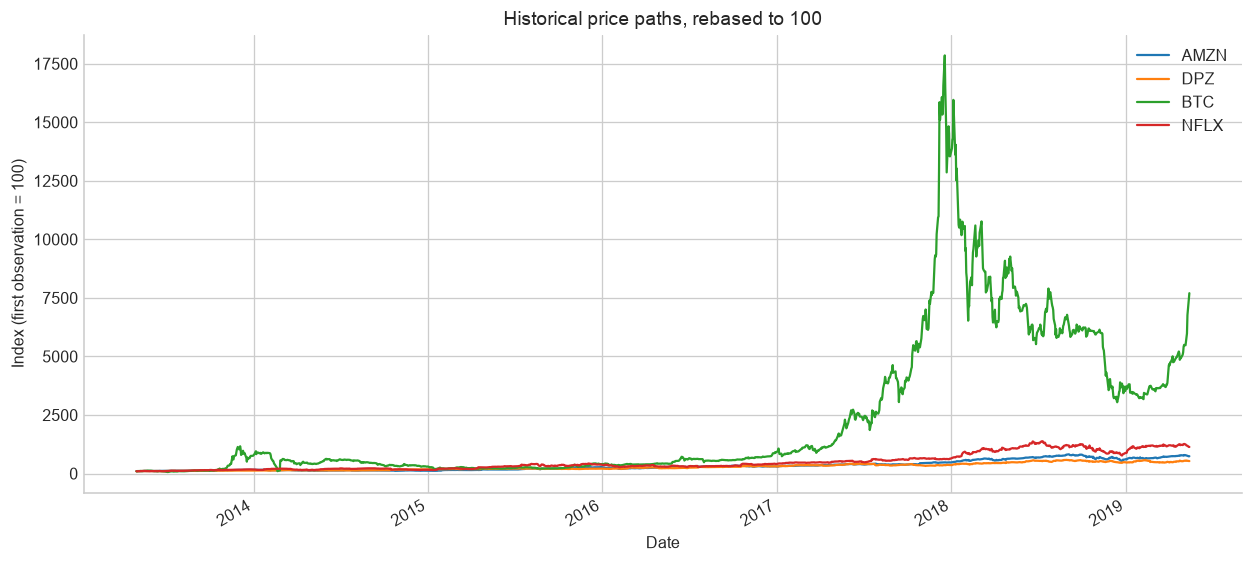

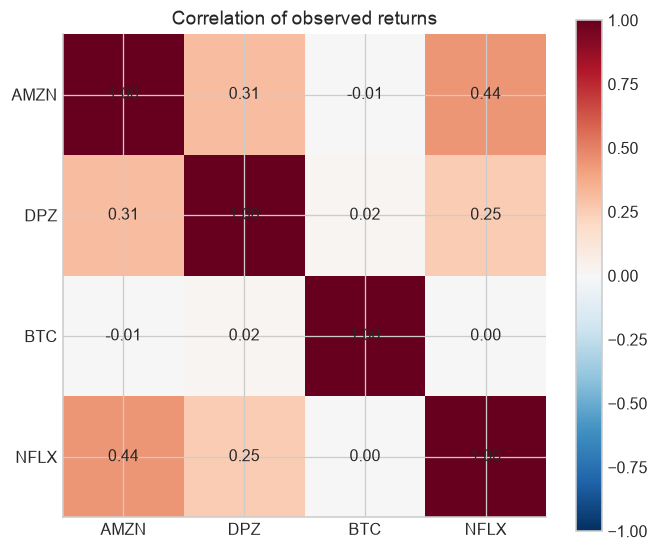

In [3]:
returns = prices.pct_change(fill_method=None)
fig, ax = plt.subplots()
(prices / prices.iloc[0] * 100).plot(ax=ax, linewidth=1.4)
ax.set(title="Historical price paths, rebased to 100", ylabel="Index (first observation = 100)", xlabel="Date")
fig.tight_layout(); fig.savefig(OUT / "normalized_prices.png"); plt.show()
fig, ax = plt.subplots(figsize=(6, 5))
corr = returns.corr()
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(4), assets); ax.set_yticks(range(4), assets)
for i in range(4):
    for j in range(4): ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center")
ax.set_title("Correlation of observed returns"); fig.colorbar(im, ax=ax)
fig.tight_layout(); fig.savefig(OUT / "return_correlations.png"); plt.show()

## 3. Causal features and prediction target
For each asset, use current and lagged returns, 5/10/20-observation momentum, moving-average ratios and rolling volatility. All features at time *t* use prices at or before *t*. Models predict the next return, then reconstruct price as `price[t] × (1 + predicted_return)`.

Predicting returns avoids making the model memorize historical price levels. Prediction occurs **after the current price is available**. This dataset has no verified intraday timestamps, volume, OHLC fields, fundamentals or news; cross-asset features are omitted to avoid assumptions about synchronized market closes.

In [4]:
def make_features(series):
    r = series.pct_change(fill_method=None)
    x = pd.DataFrame(index=series.index)
    for lag in range(6):
        x[f"return_lag_{lag}"] = r.shift(lag)
    for window in (5, 10, 20):
        x[f"momentum_{window}"] = series.pct_change(window, fill_method=None)
        x[f"ma_ratio_{window}"] = series / series.rolling(window).mean() - 1
        x[f"volatility_{window}"] = r.rolling(window).std()
    return x

# Verify features do not change when future observations are removed.
for asset in assets:
    pd.testing.assert_frame_equal(make_features(prices[asset]).iloc[:300],
                                  make_features(prices[asset].iloc[:300]))
print("Causal feature check passed for all four assets.")

Causal feature check passed for all four assets.


## 4. Chronological experiment
Use approximately 70% training, 15% validation and 15% test observations. Purge one origin at each boundary so that the preceding partition's labels end strictly before the next partition begins. Scaling is fitted inside each Ridge pipeline using training data only.

Compare persistence, Ridge (`alpha` = 1, 10, 100) and Random Forest (minimum leaf size = 5, 20; 150 trees). Choose each model family's parameter by validation price RMSE. Select the overall winner, including persistence, by validation RMSE **before inspecting the test set**. Refit the chosen family configurations on all pre-test labeled data, then evaluate once on the test set.

The test is a fixed-model, rolling one-step evaluation: each prediction may use observed prices up to its origin date. It is not a multi-step forecast made at the start of the test period.

In [5]:
def metrics(actual, predicted, current):
    actual, predicted, current = map(np.asarray, (actual, predicted, current))
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "MAPE_pct": np.mean(np.abs((actual-predicted)/actual))*100,
            "R2": r2_score(actual, predicted),
            "Direction_accuracy_pct": np.mean(np.sign(actual-current)==np.sign(predicted-current))*100}

validation_rows, test_rows, predictions, splits, forecasts = [], [], [], [], []
selected_models = {}
for asset in assets:
    s = prices[asset]
    x = make_features(s)
    frame = x.copy()
    frame["current"] = s
    frame["target"] = s.shift(-1)
    frame["target_return"] = s.shift(-1)/s - 1
    frame["target_date"] = pd.Series(s.index, index=s.index).shift(-1)
    frame = frame.dropna()
    feature_cols = list(x.columns)
    n = len(frame); cut1, cut2 = int(n*.70), int(n*.85)
    train, valid, test = frame.iloc[:cut1-1], frame.iloc[cut1:cut2-1], frame.iloc[cut2:]
    pretest = frame.iloc[:cut2-1]
    assert train.target_date.max() < valid.index.min()
    assert pretest.target_date.max() < test.index.min()
    splits.append({"Asset": asset, "Train_rows": len(train), "Validation_rows": len(valid),
                   "Test_rows": len(test), "Train_origin_end": str(train.index.max().date()),
                   "Validation_origin_start": str(valid.index.min().date()),
                   "Test_origin_start": str(test.index.min().date()),
                   "Test_target_end": str(test.target_date.max().date())})
    candidates = {f"Ridge alpha={a}": make_pipeline(StandardScaler(), Ridge(alpha=a)) for a in (1.,10.,100.)}
    candidates.update({f"RandomForest leaf={leaf}": RandomForestRegressor(n_estimators=150,
        min_samples_leaf=leaf, max_depth=8, max_features=.8, random_state=SEED, n_jobs=-1) for leaf in (5,20)})
    scores = {"Persistence": metrics(valid.target, valid.current, valid.current)["RMSE"]}
    validation_rows.append({"Asset": asset, "Candidate": "Persistence", "RMSE": scores["Persistence"]})
    for name, estimator in candidates.items():
        estimator.fit(train[feature_cols], train.target_return)
        pred = valid.current.to_numpy() * (1 + estimator.predict(valid[feature_cols]))
        scores[name] = metrics(valid.target, pred, valid.current)["RMSE"]
        validation_rows.append({"Asset": asset, "Candidate": name, "RMSE": scores[name]})
    winner = min(scores, key=scores.get)
    family_names = ["Persistence"] + [min([k for k in candidates if k.startswith(f)], key=scores.get)
                                      for f in ("Ridge", "RandomForest")]
    for name in family_names:
        model = None
        if name == "Persistence":
            pred = test.current.to_numpy()
        else:
            model = clone(candidates[name]).fit(pretest[feature_cols], pretest.target_return)
            pred = test.current.to_numpy() * (1 + model.predict(test[feature_cols]))
        test_rows.append({"Asset": asset, "Model": name, "Selected_on_validation": name == winner,
                          **metrics(test.target, pred, test.current)})
        predictions.append(pd.DataFrame({"Asset": asset, "Model": name, "Origin_date": test.index,
            "Target_date": test.target_date.to_numpy(), "Current": test.current.to_numpy(),
            "Actual": test.target.to_numpy(), "Predicted": pred}))
    # After evaluation, fit the validation-selected model to all available labeled observations.
    final_model = None if winner == "Persistence" else clone(candidates[winner]).fit(frame[feature_cols], frame.target_return)
    latest_x = x.iloc[[-1]]
    next_return = 0. if final_model is None else float(final_model.predict(latest_x)[0])
    forecasts.append({"Asset": asset, "Selected_model": winner, "As_of": str(s.index[-1].date()),
                      "Last_observed_price": float(s.iloc[-1]),
                      "Next_observation_prediction": float(s.iloc[-1]*(1+next_return))})
    selected_models[asset] = {"model": final_model, "name": winner, "features": feature_cols,
                              "as_of": str(s.index[-1].date()), "baseline": final_model is None}

validation = pd.DataFrame(validation_rows)
results = pd.DataFrame(test_rows)
predictions = pd.concat(predictions, ignore_index=True)
splits = pd.DataFrame(splits)
forecasts = pd.DataFrame(forecasts)
for name, table in {"validation_scores": validation, "test_metrics": results,
                    "test_predictions": predictions, "split_details": splits,
                    "historical_next_observation_forecast": forecasts}.items():
    table.to_csv(OUT / f"{name}.csv", index=False)
joblib.dump(selected_models, OUT / "selected_models.joblib")
display(splits)
display(validation.round(4))
display(results.round(4))

,Asset,Train_rows,Validation_rows,Test_rows,Train_origin_end,Validation_origin_start,Test_origin_start,Test_target_end
0,AMZN,1048,224,225,2017-07-26,2017-07-28,2018-06-20,2019-05-14
1,DPZ,1048,224,225,2017-07-26,2017-07-28,2018-06-20,2019-05-14
2,BTC,1048,224,225,2017-07-26,2017-07-28,2018-06-20,2019-05-14
3,NFLX,1048,224,225,2017-07-26,2017-07-28,2018-06-20,2019-05-14


,Asset,Candidate,RMSE
0,AMZN,Persistence,22.2368
1,AMZN,Ridge alpha=1.0,21.8908
2,AMZN,Ridge alpha=10.0,21.8949
3,AMZN,Ridge alpha=100.0,21.9037
4,AMZN,RandomForest leaf=5,22.0456
5,AMZN,RandomForest leaf=20,21.9469
6,DPZ,Persistence,3.4192
7,DPZ,Ridge alpha=1.0,3.3863
8,DPZ,Ridge alpha=10.0,3.3837
9,DPZ,Ridge alpha=100.0,3.3820


,Asset,Model,Selected_on_validation,MAE,RMSE,MAPE_pct,R2,Direction_accuracy_pct
0,AMZN,Persistence,False,27.3605,38.5079,1.6013,0.9271,0.4444
1,AMZN,Ridge alpha=1.0,True,27.6854,38.7120,1.6226,0.9263,54.2222
2,AMZN,RandomForest leaf=20,False,27.5984,38.8247,1.6167,0.9259,56.4444
3,DPZ,Persistence,False,3.9058,5.0695,1.4710,0.9011,0.4444
4,DPZ,Ridge alpha=100.0,True,3.9496,5.0792,1.4893,0.9007,50.6667
5,DPZ,RandomForest leaf=20,False,3.9437,5.1141,1.4876,0.8994,49.7778
6,BTC,Persistence,True,138.5141,223.6568,2.5875,0.9744,0.0000
7,BTC,Ridge alpha=100.0,False,152.4952,244.2766,2.8439,0.9695,49.3333
8,BTC,RandomForest leaf=20,False,145.5620,229.5640,2.7208,0.9730,50.2222
9,NFLX,Persistence,False,7.0928,9.2955,2.1278,0.9417,0.4444


## 5. Evaluate and visualize
MAE and RMSE are in dataset price units; MAPE is a percentage. R² measures price fit but a high R² alone does not demonstrate useful market prediction. Compare each model against persistence. Direction accuracy uses three signs (down, unchanged, up); persistence always predicts unchanged, so its direction score is not a 50% random-direction benchmark. No trading profitability is claimed.

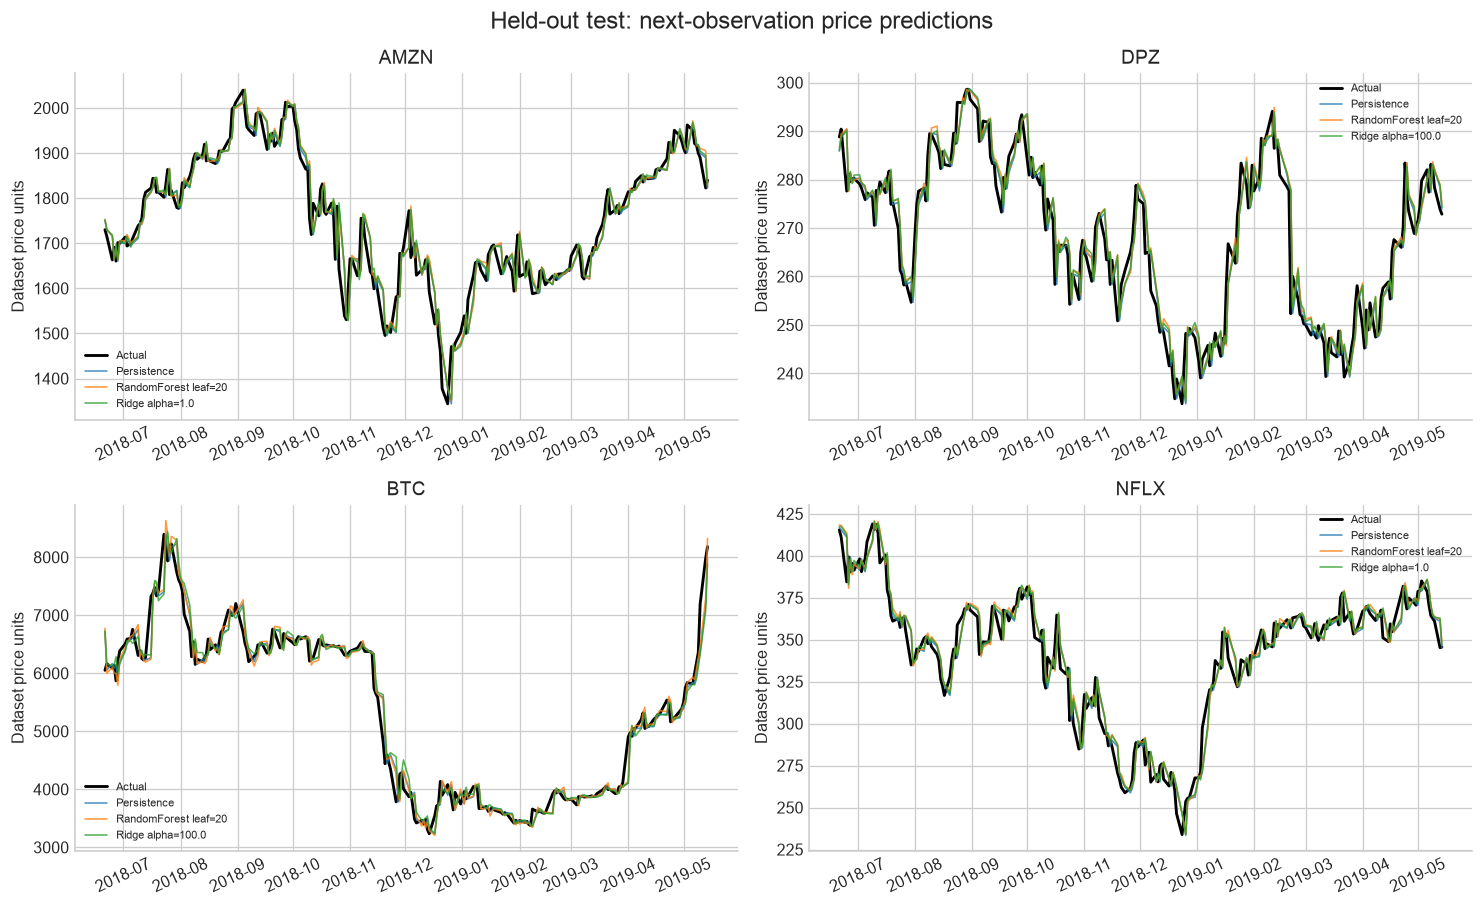

### Observed findings
- **AMZN**: validation selected **Ridge alpha=1.0**. Test RMSE = **38.7120**; persistence RMSE = **38.5079**; RMSE reduction = **-0.53%** (negative means worse).
- **DPZ**: validation selected **Ridge alpha=100.0**. Test RMSE = **5.0792**; persistence RMSE = **5.0695**; RMSE reduction = **-0.19%** (negative means worse).
- **BTC**: validation selected **Persistence**. Test RMSE = **223.6568**; persistence RMSE = **223.6568**; RMSE reduction = **0.00%** (negative means worse).
- **NFLX**: validation selected **Ridge alpha=1.0**. Test RMSE = **9.3462**; persistence RMSE = **9.2955**; RMSE reduction = **-0.54%** (negative means worse).

All split, feature-causality and metric checks passed.


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, asset in zip(axes.flat, assets):
    p = predictions[predictions.Asset == asset]
    observed = p[p.Model == "Persistence"]
    ax.plot(observed.Target_date, observed.Actual, label="Actual", color="black", linewidth=1.8)
    for name, g in p.groupby("Model"):
        ax.plot(g.Target_date, g.Predicted, label=name, alpha=.8, linewidth=1)
    ax.set(title=asset, ylabel="Dataset price units")
    ax.tick_params(axis="x", rotation=25); ax.legend(fontsize=7)
fig.suptitle("Held-out test: next-observation price predictions", fontsize=15)
fig.tight_layout(); fig.savefig(OUT / "test_predictions.png"); plt.show()

summary_lines = []
for asset in assets:
    rows = results[results.Asset == asset]
    selected = rows[rows.Selected_on_validation].iloc[0]
    baseline = rows[rows.Model == "Persistence"].iloc[0]
    improvement = (1-selected.RMSE/baseline.RMSE)*100
    summary_lines.append(f"- **{asset}**: validation selected **{selected.Model}**. Test RMSE = **{selected.RMSE:.4f}**; persistence RMSE = **{baseline.RMSE:.4f}**; RMSE reduction = **{improvement:.2f}%** (negative means worse).")
display(Markdown("### Observed findings\n" + "\n".join(summary_lines)))
assert np.isfinite(results[["MAE", "RMSE", "MAPE_pct", "R2", "Direction_accuracy_pct"]].to_numpy()).all()
assert len(results) == 12
assert results.groupby("Asset").Selected_on_validation.sum().eq(1).all()
assert predictions.groupby(["Asset", "Model"]).size().nunique() == 1
print("All split, feature-causality and metric checks passed.")

## 6. Historical inference example
The saved final models are refitted after test evaluation. Their predictions below are anchored at the **last date in the supplied historical CSV**, not at today's market. The next observation date is unknown; no calendar date is invented. These predictions have no observed target in this file and therefore cannot be scored. No calibrated uncertainty intervals are available.

In [7]:
display(forecasts.round(4))
print("Saved models and evaluation artifacts to:", OUT.resolve())

,Asset,Selected_model,As_of,Last_observed_price,Next_observation_prediction
0,AMZN,Ridge alpha=1.0,2019-05-14,1840.1200,1846.4688
1,DPZ,Ridge alpha=100.0,2019-05-14,272.8600,272.6242
2,BTC,Persistence,2019-05-14,8183.8301,8183.8301
3,NFLX,Ridge alpha=1.0,2019-05-14,345.6100,346.4779


Saved models and evaluation artifacts to: /Users/tirumalarajavardhan/Documents/Codex/2026-09-29/so-x20/outputs/stock-market-project/results


## 7. Conclusion, limitations and future work
The findings above determine whether ML adds value over a simple persistence baseline. A result where persistence wins is a valid experimental conclusion; accuracy must not be fabricated or inferred from a visually close price plot.

Limitations include a small historical sample ending in 2019, unknown source adjustment conventions, changing market regimes, missing volume/news data and unsynchronized asset calendars. One chronological test period does not establish robustness. Feature selection and hyperparameter search are deliberately limited. No transaction costs, strategy backtest, live data or deployment is included.

Future work: verify the original Kaggle source and license, obtain correctly adjusted and timestamped data, add multiple expanding-window validation folds, evaluate return errors and stability across regimes, and estimate uncertainty with temporally valid calibration.

### Viva preparation
- **Why not a random split?** It can mix future regimes into training and overstate forecasting quality.
- **Why shift the target?** The next observation is the unknown outcome; current prices remain inputs.
- **Why remove a boundary row?** Prevent label horizons from reaching into the next partition.
- **Why a pipeline?** The scaler learns only from the data used to fit the model.
- **Why persistence?** Prices are strongly dependent on their previous value; complex models must justify their extra complexity.
- **Why returns as the target?** They reduce dependence on absolute historical price levels, though predictability is still uncertain.
- **Why no LSTM?** A small dataset and a quick reproducible study favor simpler models with a defensible baseline.
- **Can this predict today's prices?** No. The supplied data ends in 2019; the inference example is historical.

### Attribution
Input: user-provided `portfolio_data.csv`; Kaggle origin reported by user, exact source pending. Implementation uses pandas, NumPy, Matplotlib, scikit-learn, joblib and Jupyter. Student name, institution and internship details should be added before submission.